Script en Python para entrenar y evaluar un Árbol de Decisión comparando la Representación 1 (Z-score), la Representación 2 (Binning estándar) y la Representación 3 (Binning con Atipia Celular agrupada) mediante Validación Cruzada Estratificada de 5 pliegues (5-Fold Stratified CV)


--- RESULTADOS COMPARATIVOS (TRES ENFOQUES) ---
                 Métrica Rep. 1: Z-Score (9 vars) Rep. 2: Binning (9 vars) Rep. 3: Binning Agrupado (7 vars)
    Exactitud (Accuracy)          0.9313 ± 0.0202          0.9600 ± 0.0147                   0.9614 ± 0.0073
   Precisión (Precision)                   0.9154                   0.9389                            0.9447
   Sensibilidad (Recall)                   0.8838                   0.9459                            0.9461
Puntuación F1 (F1-Score)                   0.8986                   0.9418                            0.9442

✓ Imagen del árbol guardada con éxito en: ..\reports\figures\arbol_decision_atipia_agrupada.png


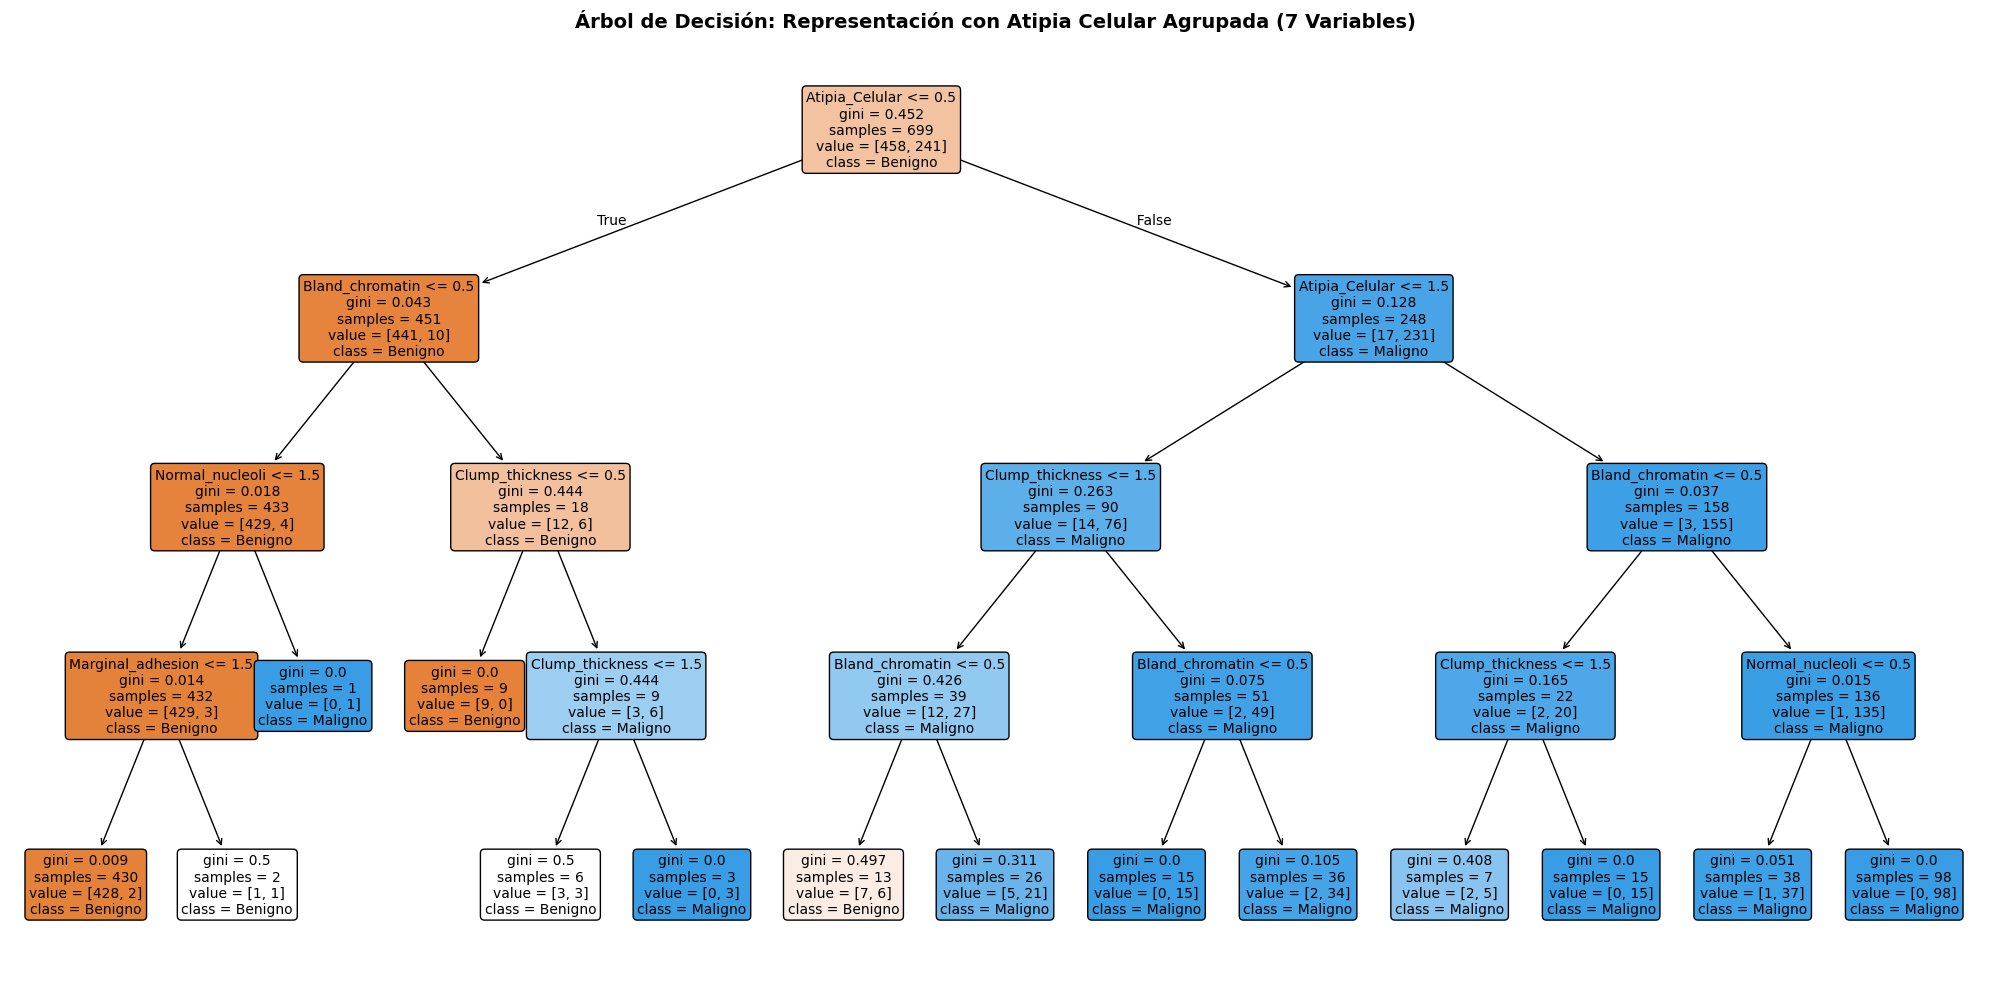

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# ==============================================================================
# 1. CARGA DEL DATASET BASE Y PREPARACIÓN DE ENTRADAS
# ==============================================================================
feature_cols = [
    'Clump_thickness',
    'Uniformity_of_cell_size',
    'Uniformity_of_cell_shape',
    'Marginal_adhesion',
    'Single_epithelial_cell_size',
    'Bare_nuclei',
    'Bland_chromatin',
    'Normal_nucleoli',
    'Mitoses',
]

df = pd.read_csv('../data/breast_cancer_original.csv')
if 'Sample_code_number' in df.columns:
  df = df.drop(columns=['Sample_code_number'])

# Imputación de Bare_nuclei con la mediana
df['Bare_nuclei'] = pd.to_numeric(df['Bare_nuclei'].replace('?', np.nan))
df['Bare_nuclei'] = df['Bare_nuclei'].fillna(df['Bare_nuclei'].median())

# Variable objetivo binaria: 2 (Benigno) -> 0, 4 (Maligno) -> 1
y = df['Class'].map({2: 0, 4: 1}).values

# ==============================================================================
# 2. CONSTRUCCIÓN DE LAS TRES REPRESENTACIONES
# ==============================================================================
# Rep 1: Z-Score (9 variables continuas estandarizadas)
scaler = StandardScaler()
X_rep1 = scaler.fit_transform(df[feature_cols])

# Rep 2: Binning Original (9 variables discretizadas del 1 al 10 en 0, 1, 2)
bins = [-np.inf, 3, 6, np.inf]
labels = [0, 1, 2]
X_rep2 = pd.DataFrame()
for col in feature_cols:
  X_rep2[col] = pd.cut(df[col], bins=bins, labels=labels).astype(int)

# Rep 3: Binning con Atipia Celular Agrupada (7 variables)
# Promediamos las 3 variables con alta correlación y misma mediana
df['Indice_Atipia_Celular'] = df[[
    'Uniformity_of_cell_size',
    'Uniformity_of_cell_shape',
    'Bare_nuclei',
]].mean(axis=1)

cols_restantes = [
    'Clump_thickness',
    'Marginal_adhesion',
    'Single_epithelial_cell_size',
    'Bland_chromatin',
    'Normal_nucleoli',
    'Mitoses',
]
features_rep3 = cols_restantes + ['Indice_Atipia_Celular']

X_rep3 = pd.DataFrame()
for col in features_rep3:
  X_rep3[col] = pd.cut(df[col], bins=bins, labels=labels).astype(int)
X_rep3.rename(
    columns={'Indice_Atipia_Celular': 'Atipia_Celular'}, inplace=True
)

# ==============================================================================
# 3. EVALUACIÓN COMPARATIVA (5-Fold Stratified CV)
# ==============================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1']

# Instanciamos los 3 modelos con max_depth=4 para comparación justa
dt_rep1 = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_rep2 = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_rep3 = DecisionTreeClassifier(max_depth=4, random_state=42)

res_rep1 = cross_validate(dt_rep1, X_rep1, y, cv=cv, scoring=metricas)
res_rep2 = cross_validate(dt_rep2, X_rep2, y, cv=cv, scoring=metricas)
res_rep3 = cross_validate(dt_rep3, X_rep3, y, cv=cv, scoring=metricas)

# Tabla comparativa de resultados
df_resultados = pd.DataFrame({
    'Métrica': [
        'Exactitud (Accuracy)',
        'Precisión (Precision)',
        'Sensibilidad (Recall)',
        'Puntuación F1 (F1-Score)',
    ],
    'Rep. 1: Z-Score (9 vars)': [
        (
            f"{res_rep1['test_accuracy'].mean():.4f} ±"
            f" {res_rep1['test_accuracy'].std():.4f}"
        ),
        f"{res_rep1['test_precision'].mean():.4f}",
        f"{res_rep1['test_recall'].mean():.4f}",
        f"{res_rep1['test_f1'].mean():.4f}",
    ],
    'Rep. 2: Binning (9 vars)': [
        (
            f"{res_rep2['test_accuracy'].mean():.4f} ±"
            f" {res_rep2['test_accuracy'].std():.4f}"
        ),
        f"{res_rep2['test_precision'].mean():.4f}",
        f"{res_rep2['test_recall'].mean():.4f}",
        f"{res_rep2['test_f1'].mean():.4f}",
    ],
    'Rep. 3: Binning Agrupado (7 vars)': [
        (
            f"{res_rep3['test_accuracy'].mean():.4f} ±"
            f" {res_rep3['test_accuracy'].std():.4f}"
        ),
        f"{res_rep3['test_precision'].mean():.4f}",
        f"{res_rep3['test_recall'].mean():.4f}",
        f"{res_rep3['test_f1'].mean():.4f}",
    ],
})

print('\n--- RESULTADOS COMPARATIVOS (TRES ENFOQUES) ---')
print(df_resultados.to_string(index=False))

# ==============================================================================
# 4. GRAFICAR Y EXPORTAR LA IMAGEN DEL ÁRBOL
# ==============================================================================
# Entrenamos el árbol final con las 7 características agrupadas
dt_rep3.fit(X_rep3, y)

# Creamos la figura en alta resolución
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    dt_rep3,
    feature_names=list(X_rep3.columns),
    class_names=['Benigno', 'Maligno'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
)
plt.title(
    'Árbol de Decisión: Representación con Atipia Celular Agrupada (7'
    ' Variables)',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout()

# Guardar la imagen en reports/figures/ siguiendo el estándar Cookiecutter
carpeta_figuras = os.path.join('..', 'reports', 'figures')
os.makedirs(carpeta_figuras, exist_ok=True)
ruta_imagen = os.path.join(carpeta_figuras, 'arbol_decision_atipia_agrupada.png')

plt.savefig(ruta_imagen, dpi=300, bbox_inches='tight')
print(f'\n✓ Imagen del árbol guardada con éxito en: {ruta_imagen}')

plt.show()
plt.close()